# Proyecto Final — Estadística Matemática
## Modelos paramétricos con datos de la WNBA (2023–2025)

**Pasos 2, 3 y 4 del proyecto:**
2. Proponer modelos paramétricos para cada variable
3. Estimar parámetros por **método de momentos (MM)** y **máxima verosimilitud (MV)**
4. Graficar histogramas (`density=True`, equivalente a `probability=TRUE` en R) con las densidades ajustadas y elegir visualmente el mejor modelo

**Datos:** box scores de ESPN (SportsDataverse / `wehoop`), temporada regular 2023–2025. Cada observación es una jugadora en una temporada, con al menos 10 partidos jugados.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from pathlib import Path

plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["figure.dpi"] = 110

FIG = Path("../figuras")
FIG.mkdir(exist_ok=True)

df = pd.read_csv("../data/wnba_jugadoras_2023_2025.csv")
print(df.shape)
df.head()

(440, 13)


,temporada,jugadora,equipo,posicion,partidos,minutos_pp,puntos_pp,rebotes_pp,asistencias_pp,tl_anotados,tl_intentados,pct_tl,pct_tiros_campo
0,2023,Jewell Loyd,SEA,G,39,35.10,24.87,4.67,3.51,255,287,0.8885,0.3725
1,2023,Breanna Stewart,NY,F,42,33.93,22.40,9.14,3.81,208,245,0.8490,0.4583
2,2023,A'ja Wilson,LV,F,42,30.62,22.40,9.29,1.57,238,293,0.8123,0.5527
3,2023,Napheesa Collier,MIN,F,38,33.00,21.47,8.39,2.53,170,202,0.8416,0.4888
4,2023,Arike Ogunbowale,DAL,G,41,36.95,21.15,3.44,4.54,134,153,0.8758,0.3961


## 1. Exploración de los datos

In [2]:
variables = ["minutos_pp", "puntos_pp", "rebotes_pp",
             "asistencias_pp", "pct_tl", "pct_tiros_campo"]

resumen = df[variables].describe().T
resumen["asimetria"] = df[variables].skew()
resumen.round(3)

,count,mean,std,min,25%,50%,75%,max,asimetria
minutos_pp,440.0,20.323,8.719,2.620,12.898,20.890,27.970,38.44,-0.108
puntos_pp,440.0,8.207,5.498,0.120,3.815,7.035,11.742,26.74,0.770
rebotes_pp,440.0,3.463,2.316,0.150,1.738,2.885,4.600,13.06,1.131
asistencias_pp,440.0,2.027,1.645,0.000,0.785,1.650,2.778,9.02,1.433
pct_tl,332.0,0.780,0.092,0.472,0.729,0.788,0.849,0.96,-0.676
pct_tiros_campo,385.0,0.432,0.068,0.257,0.388,0.425,0.480,0.65,0.282


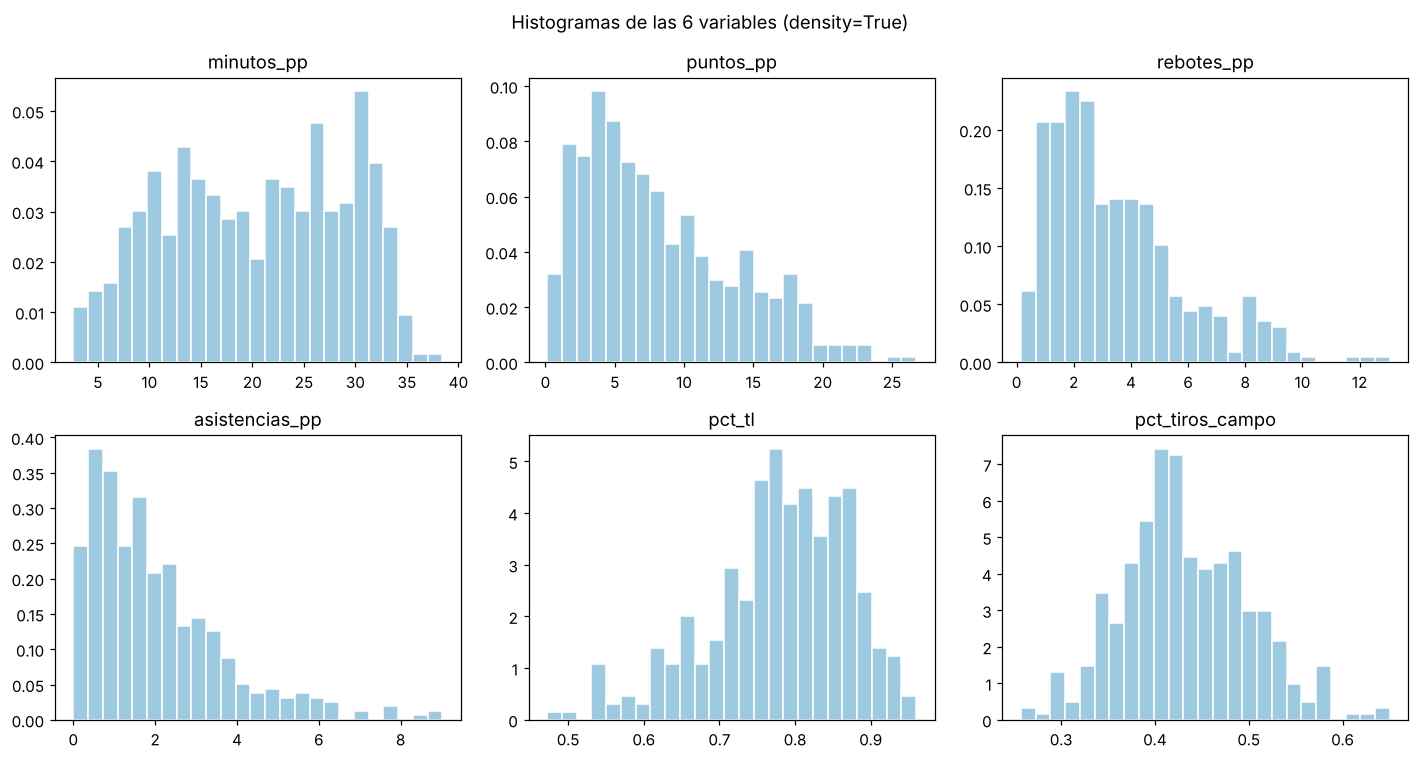

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, v in zip(axes.flat, variables):
    ax.hist(df[v].dropna(), bins=25, density=True, color="#9ecae1", edgecolor="white")
    ax.set_title(v)
fig.suptitle("Histogramas de las 6 variables (density=True)")
fig.tight_layout()
fig.savefig(FIG / "histogramas_exploracion.png", dpi=150)
plt.show()

## 2. Funciones de estimación

Notación (la misma que usaremos en el reporte):

| Modelo | Parámetros | Media | Varianza |
|---|---|---|---|
| Normal$(\mu,\sigma^2)$ | $\mu,\sigma^2$ | $\mu$ | $\sigma^2$ |
| Exponencial$(\theta)$ | $\theta$ = media | $\theta$ | $\theta^2$ |
| Gamma$(\alpha,\beta)$ | forma $\alpha$, tasa $\beta$ | $\alpha/\beta$ | $\alpha/\beta^2$ |
| Lognormal$(\mu,\sigma^2)$ | $\log X\sim N(\mu,\sigma^2)$ | $e^{\mu+\sigma^2/2}$ | $(e^{\sigma^2}-1)e^{2\mu+\sigma^2}$ |
| Beta$(\alpha,\beta)$ | $\alpha,\beta$ | $\frac{\alpha}{\alpha+\beta}$ | $\frac{\alpha\beta}{(\alpha+\beta)^2(\alpha+\beta+1)}$ |

**Método de momentos:** igualamos $\bar X$ y $S^2=\frac1n\sum(X_i-\bar X)^2$ a la media y varianza teóricas y despejamos:

- Normal: $\hat\mu=\bar X$, $\hat\sigma^2=S^2$
- Exponencial: $\hat\theta=\bar X$
- Gamma: $\hat\alpha=\bar X^2/S^2$, $\hat\beta=\bar X/S^2$
- Lognormal: $\hat\sigma^2=\log\left(1+S^2/\bar X^2\right)$, $\hat\mu=\log\bar X-\hat\sigma^2/2$
- Beta: $c=\frac{\bar X(1-\bar X)}{S^2}-1$, $\hat\alpha=\bar X c$, $\hat\beta=(1-\bar X)c$

**Máxima verosimilitud:**

- Normal: $\hat\mu=\bar X$, $\hat\sigma^2=S^2$ (coincide con MM)
- Exponencial: $\hat\theta=\bar X$ (coincide con MM)
- Lognormal: $\hat\mu=\frac1n\sum\log X_i$, $\hat\sigma^2=\frac1n\sum(\log X_i-\hat\mu)^2$
- Gamma y Beta: no hay forma cerrada; se maximiza la log-verosimilitud numéricamente (`scipy.stats.*.fit`).

In [4]:
def momentos(x, modelo):
    """Estimadores por método de momentos."""
    m = x.mean()
    s2 = x.var(ddof=0)          # S^2 con divisor n
    if modelo == "normal":
        return {"mu": m, "sigma2": s2}
    if modelo == "exponencial":
        return {"theta": m}
    if modelo == "gamma":
        return {"alpha": m**2 / s2, "beta": m / s2}
    if modelo == "lognormal":
        sig2 = np.log(1 + s2 / m**2)
        return {"mu": np.log(m) - sig2 / 2, "sigma2": sig2}
    if modelo == "beta":
        c = m * (1 - m) / s2 - 1
        return {"alpha": m * c, "beta": (1 - m) * c}


def max_ver(x, modelo):
    """Estimadores de máxima verosimilitud."""
    if modelo == "normal":
        return {"mu": x.mean(), "sigma2": x.var(ddof=0)}
    if modelo == "exponencial":
        return {"theta": x.mean()}
    if modelo == "gamma":
        a, _, escala = stats.gamma.fit(x, floc=0)
        return {"alpha": a, "beta": 1 / escala}
    if modelo == "lognormal":
        lx = np.log(x)
        return {"mu": lx.mean(), "sigma2": lx.var(ddof=0)}
    if modelo == "beta":
        a, b, _, _ = stats.beta.fit(x, floc=0, fscale=1)
        return {"alpha": a, "beta": b}


def distribucion(modelo, p):
    """Convierte nuestros parámetros a un objeto de scipy."""
    if modelo == "normal":
        return stats.norm(loc=p["mu"], scale=np.sqrt(p["sigma2"]))
    if modelo == "exponencial":
        return stats.expon(scale=p["theta"])
    if modelo == "gamma":
        return stats.gamma(a=p["alpha"], scale=1 / p["beta"])
    if modelo == "lognormal":
        return stats.lognorm(s=np.sqrt(p["sigma2"]), scale=np.exp(p["mu"]))
    if modelo == "beta":
        return stats.beta(p["alpha"], p["beta"])


N_PARAMS = {"normal": 2, "exponencial": 1, "gamma": 2, "lognormal": 2, "beta": 2}
COLORES = {"normal": "#d62728", "exponencial": "#2ca02c", "gamma": "#1f77b4",
           "lognormal": "#ff7f0e", "beta": "#9467bd"}


def analizar(x, modelos, nombre, xlabel=None):
    """Estima por MM y MV, grafica y devuelve una tabla resumen."""
    x = np.asarray(x, dtype=float)
    filas = []
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
    grid = np.linspace(max(x.min() * 0.9, 1e-6), x.max() * 1.05, 400)
    for ax, (metodo, f) in zip(axes, [("Momentos", momentos), ("Máx. verosimilitud", max_ver)]):
        ax.hist(x, bins=25, density=True, color="#d9d9d9", edgecolor="white")
        for mod in modelos:
            p = f(x, mod)
            d = distribucion(mod, p)
            ax.plot(grid, d.pdf(grid), lw=2.2, color=COLORES[mod], label=mod.capitalize())
            loglik = d.logpdf(x).sum()
            filas.append({"modelo": mod, "metodo": metodo,
                          **{k: round(v, 4) for k, v in p.items()},
                          "log-verosimilitud": round(loglik, 2),
                          "AIC": round(2 * N_PARAMS[mod] - 2 * loglik, 2)})
        ax.set_title(f"{nombre} — {metodo}")
        ax.set_xlabel(xlabel or nombre)
        ax.legend()
    axes[0].set_ylabel("Densidad")
    fig.tight_layout()
    fig.savefig(FIG / f"ajuste_{nombre}.png", dpi=150)
    plt.show()
    return pd.DataFrame(filas)

## 3. Ajuste por variable

En cada variable comparamos 2 o 3 modelos. La gráfica de la izquierda usa estimadores de momentos y la de la derecha de máxima verosimilitud.
El **AIC** (más bajo = mejor) solo sirve de apoyo; la elección principal es **visual**, como pide el proyecto.

### 3.1 Puntos por partido
Variable positiva y con sesgo fuerte a la derecha: pocas jugadoras anotan mucho. Candidatos: **Gamma**, **Exponencial** y **Lognormal**.

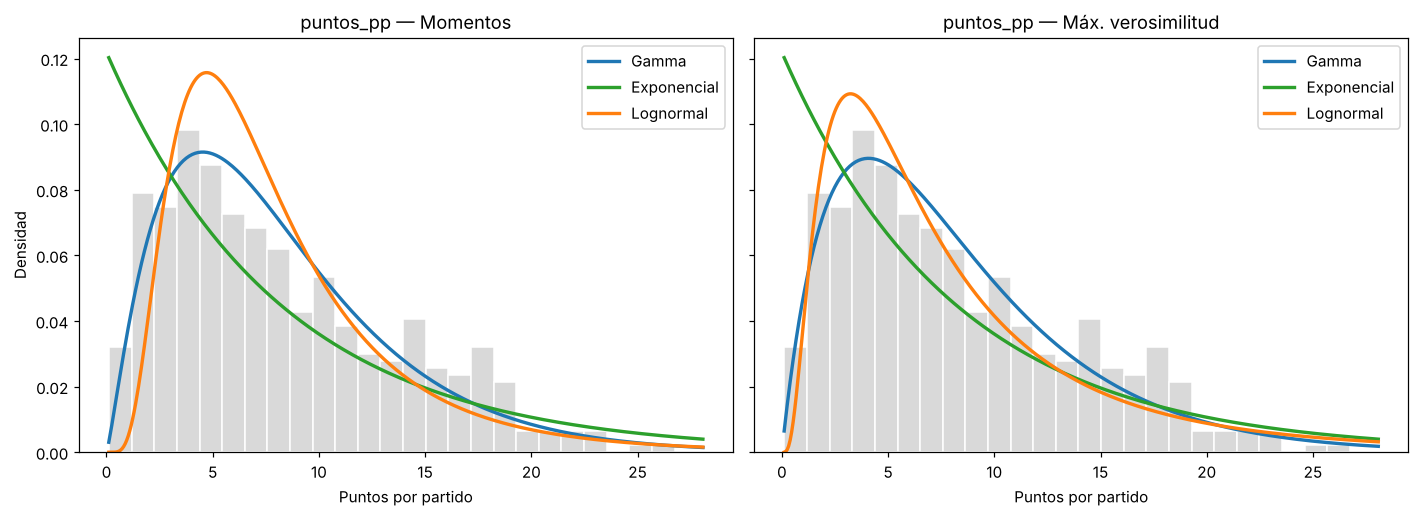

,modelo,metodo,alpha,beta,log-verosimilitud,AIC,theta,mu,sigma2
0,gamma,Momentos,2.2331,0.2721,-1317.69,2639.37,NaN,NaN,NaN
1,exponencial,Momentos,NaN,NaN,-1366.18,2734.36,8.2068,NaN,NaN
2,lognormal,Momentos,NaN,NaN,-1389.21,2782.42,NaN,1.9199,0.3701
3,gamma,Máx. verosimilitud,1.9885,0.2423,-1315.91,2635.82,NaN,NaN,NaN
4,exponencial,Máx. verosimilitud,NaN,NaN,-1366.18,2734.36,8.2068,NaN,NaN
5,lognormal,Máx. verosimilitud,NaN,NaN,-1339.53,2683.05,NaN,1.8329,0.6604


In [5]:
pts = df["puntos_pp"].dropna()
tab_pts = analizar(pts, ["gamma", "exponencial", "lognormal"], "puntos_pp", "Puntos por partido")
tab_pts

**Interpretación:** _(escribe aquí qué modelo se ve mejor y por qué)_

### 3.2 Rebotes por partido
Positiva y asimétrica. Candidatos: **Gamma** y **Lognormal**.

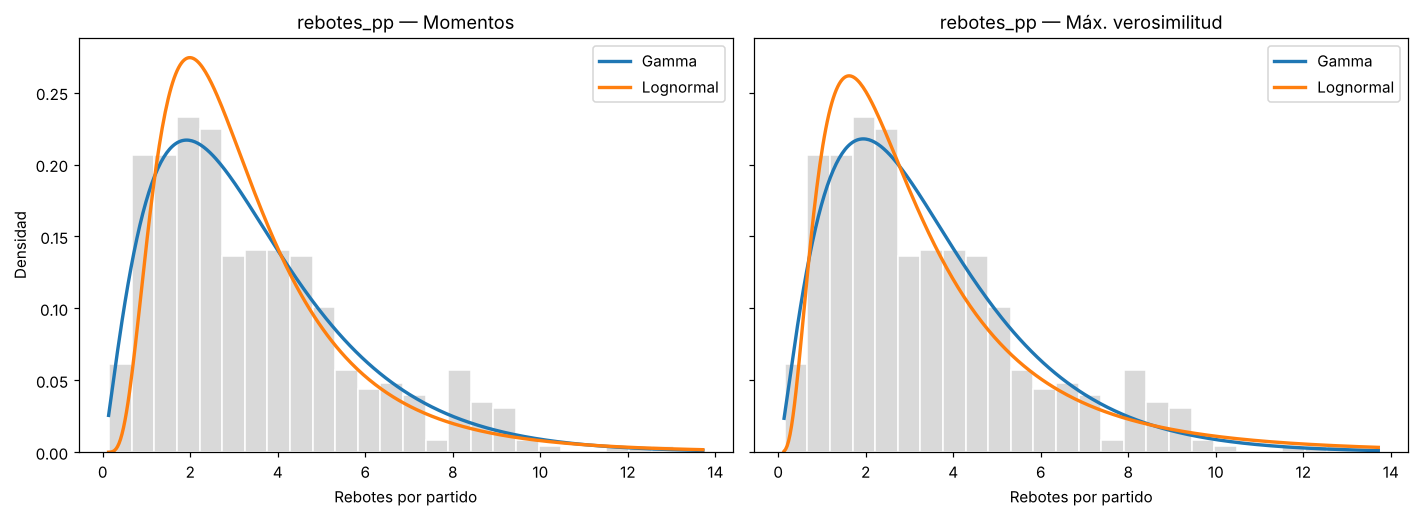

,modelo,metodo,alpha,beta,log-verosimilitud,AIC,mu,sigma2
0,gamma,Momentos,2.2398,0.6469,-917.90,1839.81,NaN,NaN
1,lognormal,Momentos,NaN,NaN,-941.97,1887.94,1.0575,0.3691
2,gamma,Máx. verosimilitud,2.2800,0.6585,-917.87,1839.73,NaN,NaN
3,lognormal,Máx. verosimilitud,NaN,NaN,-925.22,1854.44,1.0070,0.5240


In [6]:
reb = df["rebotes_pp"].dropna()
tab_reb = analizar(reb, ["gamma", "lognormal"], "rebotes_pp", "Rebotes por partido")
tab_reb

**Interpretación:** _(escribe aquí)_

### 3.3 Asistencias por partido
Muy sesgada a la derecha. Candidatos: **Exponencial** y **Gamma**.
Hay 2 jugadoras con 0.0 asistencias por partido; las quitamos porque la densidad Gamma no está definida para valores ≤ 0 en general (con $\alpha<1$ vale infinito en 0).

Observaciones: 438


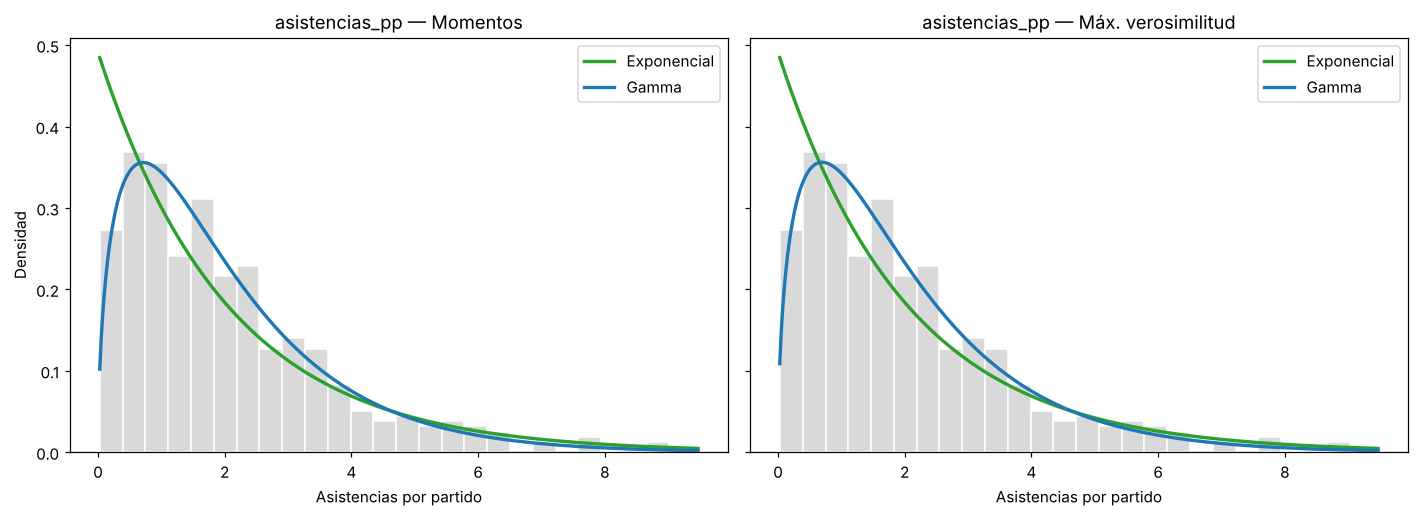

,modelo,metodo,theta,log-verosimilitud,AIC,alpha,beta
0,exponencial,Momentos,2.0365,-749.52,1501.04,NaN,NaN
1,gamma,Momentos,NaN,-728.96,1461.92,1.5399,0.7562
2,exponencial,Máx. verosimilitud,2.0365,-749.52,1501.04,NaN,NaN
3,gamma,Máx. verosimilitud,NaN,-728.94,1461.87,1.5186,0.7457


In [7]:
ast = df.loc[df["asistencias_pp"] > 0, "asistencias_pp"]
print("Observaciones:", len(ast))
tab_ast = analizar(ast, ["exponencial", "gamma"], "asistencias_pp", "Asistencias por partido")
tab_ast

**Interpretación:** _(escribe aquí)_

### 3.4 Minutos por partido (como proporción del partido)
Un partido de WNBA dura 40 minutos, así que $Y = \text{minutos}/40 \in (0,1)$. Candidatos: **Beta** y **Normal**.

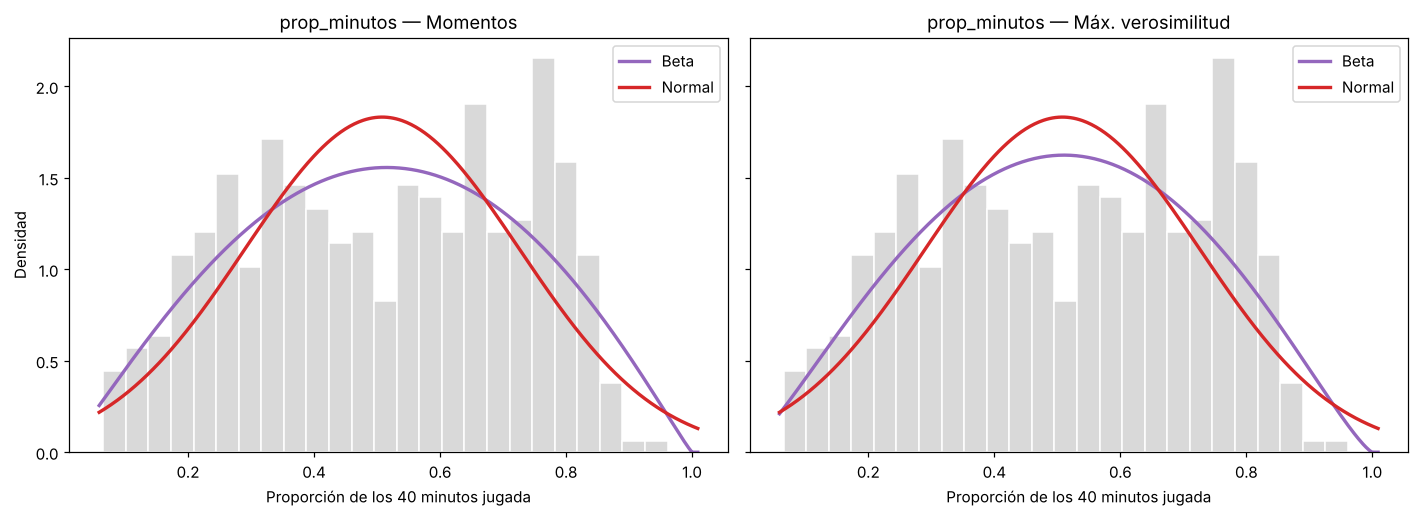

,modelo,metodo,alpha,beta,log-verosimilitud,AIC,mu,sigma2
0,beta,Momentos,2.1706,2.1016,74.79,-145.57,NaN,NaN
1,normal,Momentos,NaN,NaN,46.45,-88.90,0.5081,0.0474
2,beta,Máx. verosimilitud,2.3344,2.2791,75.58,-147.15,NaN,NaN
3,normal,Máx. verosimilitud,NaN,NaN,46.45,-88.90,0.5081,0.0474


In [8]:
mins = (df["minutos_pp"] / 40).dropna()
tab_min = analizar(mins, ["beta", "normal"], "prop_minutos", "Proporción de los 40 minutos jugada")
tab_min

**Interpretación:** _(escribe aquí)_

### 3.5 Porcentaje de tiros libres
Es una proporción en (0,1) y solo se calcula para jugadoras con 20 o más intentos. Candidatos: **Beta** y **Normal**.

Observaciones: 332


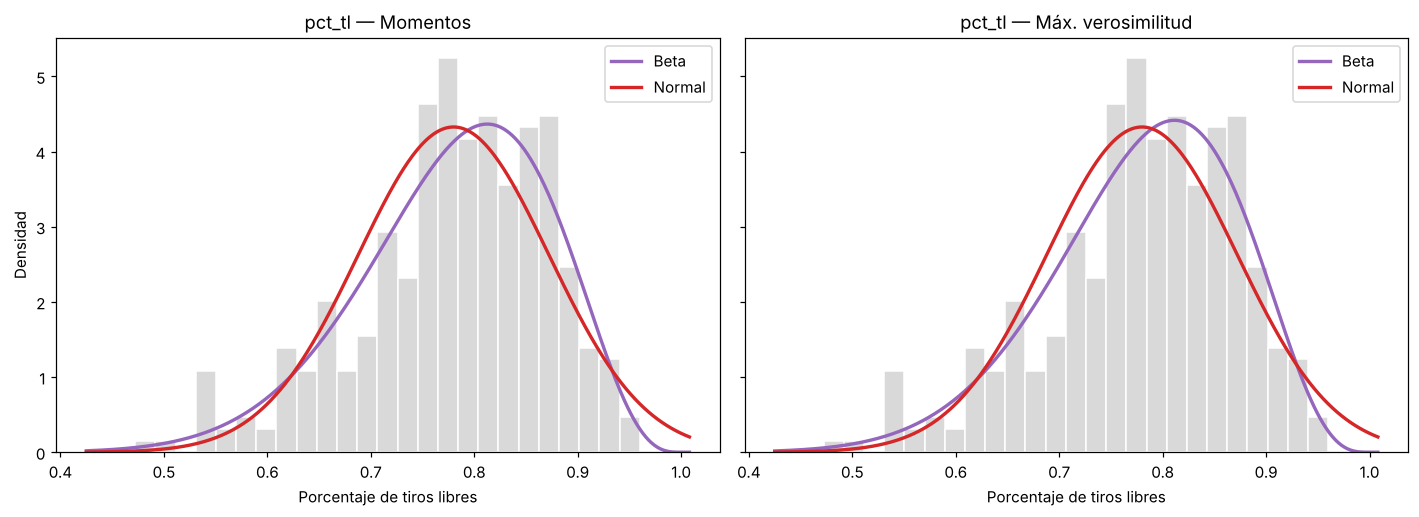

,modelo,metodo,alpha,beta,log-verosimilitud,AIC,mu,sigma2
0,beta,Momentos,14.9621,4.2203,336.17,-668.33,NaN,NaN
1,normal,Momentos,NaN,NaN,320.30,-636.59,0.78,0.0085
2,beta,Máx. verosimilitud,15.3514,4.3348,336.23,-668.46,NaN,NaN
3,normal,Máx. verosimilitud,NaN,NaN,320.30,-636.59,0.78,0.0085


In [9]:
tl = df["pct_tl"].dropna()
print("Observaciones:", len(tl))
tab_tl = analizar(tl, ["beta", "normal"], "pct_tl", "Porcentaje de tiros libres")
tab_tl

**Interpretación:** _(escribe aquí)_

### 3.6 Porcentaje de tiros de campo
Proporción en (0,1), con 50 o más intentos. Candidatos: **Normal** y **Beta**.

Observaciones: 385


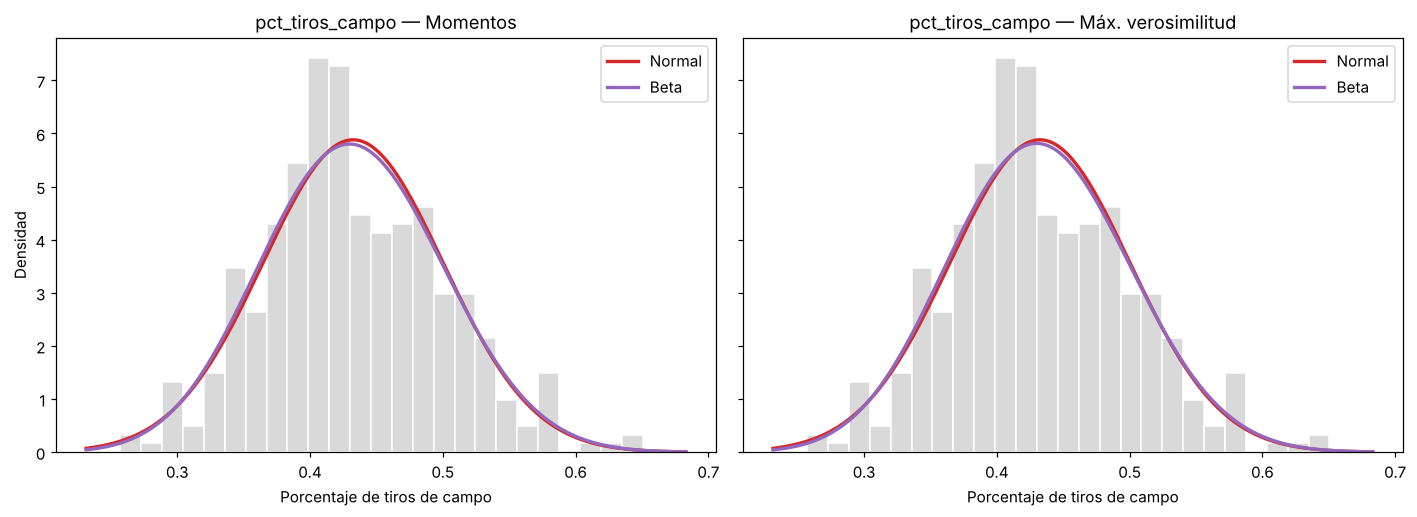

,modelo,metodo,mu,sigma2,log-verosimilitud,AIC,alpha,beta
0,normal,Momentos,0.4324,0.0046,489.65,-975.31,NaN,NaN
1,beta,Momentos,NaN,NaN,490.74,-977.48,22.6367,29.7102
2,normal,Máx. verosimilitud,0.4324,0.0046,489.65,-975.31,NaN,NaN
3,beta,Máx. verosimilitud,NaN,NaN,490.74,-977.49,22.7387,29.8327


In [10]:
tc = df["pct_tiros_campo"].dropna()
print("Observaciones:", len(tc))
tab_tc = analizar(tc, ["normal", "beta"], "pct_tiros_campo", "Porcentaje de tiros de campo")
tab_tc

**Interpretación:** _(escribe aquí)_

## 4. Resumen: mejor modelo por variable (según AIC, estimadores de MV)

In [11]:
tablas = {"puntos_pp": tab_pts, "rebotes_pp": tab_reb, "asistencias_pp": tab_ast,
          "prop_minutos": tab_min, "pct_tl": tab_tl, "pct_tiros_campo": tab_tc}

resumen = []
for var, t in tablas.items():
    mv = t[t["metodo"] == "Máx. verosimilitud"].sort_values("AIC")
    mejor = mv.iloc[0]
    resumen.append({"variable": var, "mejor modelo (AIC)": mejor["modelo"],
                    "AIC": mejor["AIC"], "segundo": mv.iloc[1]["modelo"],
                    "AIC segundo": mv.iloc[1]["AIC"]})
pd.DataFrame(resumen)

,variable,mejor modelo (AIC),AIC,segundo,AIC segundo
0,puntos_pp,gamma,2635.82,lognormal,2683.05
1,rebotes_pp,gamma,1839.73,lognormal,1854.44
2,asistencias_pp,gamma,1461.87,exponencial,1501.04
3,prop_minutos,beta,-147.15,normal,-88.90
4,pct_tl,beta,-668.46,normal,-636.59
5,pct_tiros_campo,beta,-977.49,normal,-975.31


Confirma que coincida con lo que ves en las gráficas. Esa elección visual es la que va en el reporte.
Con estos modelos seguimos al **paso 5 (intervalos de confianza)** y al **paso 6 (pruebas de hipótesis)**.

## 5. Intervalos de confianza (paso 5)

Construimos intervalos al 95% para los parámetros del modelo elegido en cada variable.

**Normal (tiros de campo): intervalos exactos.** Si $X_i\sim N(\mu,\sigma^2)$, entonces $\frac{\bar X-\mu}{s/\sqrt n}\sim t_{n-1}$ y $\frac{(n-1)s^2}{\sigma^2}\sim\chi^2_{n-1}$, con $s^2$ la varianza con divisor $n-1$:

$$\bar X \pm t_{n-1,\,0.975}\frac{s}{\sqrt n}, \qquad \left[\frac{(n-1)s^2}{\chi^2_{n-1,\,0.975}},\ \frac{(n-1)s^2}{\chi^2_{n-1,\,0.025}}\right]$$

**Gamma y Beta: intervalos asintóticos (Wald) con la información de Fisher.** Para el EMV, $\hat\theta \approx N\big(\theta,\ [nI(\theta)]^{-1}\big)$, así que

$$\hat\theta_j \pm z_{0.975}\sqrt{\big[(nI(\hat\theta))^{-1}\big]_{jj}}$$

Información de Fisher por observación ($\psi'$ = función trigamma):

$$I_{\text{Gamma}}(\alpha,\beta)=\begin{pmatrix}\psi'(\alpha) & -1/\beta\\ -1/\beta & \alpha/\beta^2\end{pmatrix}, \qquad I_{\text{Beta}}(\alpha,\beta)=\begin{pmatrix}\psi'(\alpha)-\psi'(\alpha+\beta) & -\psi'(\alpha+\beta)\\ -\psi'(\alpha+\beta) & \psi'(\beta)-\psi'(\alpha+\beta)\end{pmatrix}$$

Para la **media** del modelo ($\alpha/\beta$ en la Gamma, $\alpha/(\alpha+\beta)$ en la Beta) usamos el método delta: $\operatorname{Var}(g(\hat\theta))\approx \nabla g^\top [nI]^{-1}\nabla g$.

Como verificación, calculamos también intervalos por **bootstrap no paramétrico** (percentiles 2.5% y 97.5% de B = 1000 remuestreos).

In [12]:
from scipy.special import polygamma

trigamma = lambda x: polygamma(1, x)
Z = stats.norm.ppf(0.975)
rng = np.random.default_rng(2026)
B = 1000


def fisher(modelo, a, b):
    if modelo == "gamma":
        return np.array([[trigamma(a), -1 / b], [-1 / b, a / b**2]])
    if modelo == "beta":
        t = trigamma(a + b)
        return np.array([[trigamma(a) - t, -t], [-t, trigamma(b) - t]])


def media(modelo, a, b):
    return a / b if modelo == "gamma" else a / (a + b)


def grad_media(modelo, a, b):
    if modelo == "gamma":
        return np.array([1 / b, -a / b**2])
    return np.array([b / (a + b)**2, -a / (a + b)**2])


def ic_wald_bootstrap(x, modelo, nombre):
    x = np.asarray(x, dtype=float)
    n = len(x)
    p = max_ver(x, modelo)
    a, b = p["alpha"], p["beta"]
    cov = np.linalg.inv(n * fisher(modelo, a, b))
    se = np.sqrt(np.diag(cov))
    g = grad_media(modelo, a, b)
    se_m = np.sqrt(g @ cov @ g)

    boot = np.empty((B, 3))
    for i in range(B):
        xb = rng.choice(x, n, replace=True)
        pb = max_ver(xb, modelo)
        boot[i] = [pb["alpha"], pb["beta"], media(modelo, pb["alpha"], pb["beta"])]
    lo, hi = np.percentile(boot, [2.5, 97.5], axis=0)

    filas = []
    for j, (par, est, s) in enumerate([("alpha", a, se[0]), ("beta", b, se[1]),
                                       ("media", media(modelo, a, b), se_m)]):
        filas.append({"variable": nombre, "modelo": modelo, "parametro": par,
                      "estimacion": est, "error_est": s,
                      "IC95 Wald inf": est - Z * s, "IC95 Wald sup": est + Z * s,
                      "IC95 bootstrap inf": lo[j], "IC95 bootstrap sup": hi[j]})
    return pd.DataFrame(filas)

In [13]:
ic_gamma_beta = pd.concat([
    ic_wald_bootstrap(pts, "gamma", "puntos_pp"),
    ic_wald_bootstrap(reb, "gamma", "rebotes_pp"),
    ic_wald_bootstrap(ast, "gamma", "asistencias_pp"),
    ic_wald_bootstrap(mins, "beta", "prop_minutos"),
    ic_wald_bootstrap(tl, "beta", "pct_tl"),
], ignore_index=True)
ic_gamma_beta.round(4)

,variable,modelo,parametro,estimacion,error_est,IC95 Wald inf,IC95 Wald sup,IC95 bootstrap inf,IC95 bootstrap sup
0,puntos_pp,gamma,alpha,1.9885,0.1245,1.7445,2.2324,1.7860,2.2196
1,puntos_pp,gamma,beta,0.2423,0.0172,0.2085,0.2761,0.2160,0.2703
2,puntos_pp,gamma,media,8.2068,0.2775,7.6630,8.7506,7.7147,8.7598
3,rebotes_pp,gamma,alpha,2.2800,0.1439,1.9979,2.5620,2.0617,2.5458
4,rebotes_pp,gamma,beta,0.6585,0.0465,0.5674,0.7495,0.5821,0.7498
5,rebotes_pp,gamma,media,3.4626,0.1093,3.2483,3.6769,3.2514,3.6958
6,asistencias_pp,gamma,alpha,1.5186,0.0935,1.3353,1.7019,1.3589,1.6984
7,asistencias_pp,gamma,beta,0.7457,0.0543,0.6393,0.8520,0.6519,0.8545
8,asistencias_pp,gamma,media,2.0365,0.0790,1.8817,2.1913,1.8921,2.1954
9,prop_minutos,beta,alpha,2.3344,0.1507,2.0390,2.6298,2.1036,2.5950


In [14]:
# Normal: intervalos exactos para mu y sigma^2 (porcentaje de tiros de campo)
n = len(tc)
xbar = tc.mean()
s2 = tc.var(ddof=1)
t = stats.t.ppf(0.975, n - 1)
ic_mu = (xbar - t * np.sqrt(s2 / n), xbar + t * np.sqrt(s2 / n))
ic_s2 = ((n - 1) * s2 / stats.chi2.ppf(0.975, n - 1), (n - 1) * s2 / stats.chi2.ppf(0.025, n - 1))
ic_normal = pd.DataFrame([
    {"variable": "pct_tiros_campo", "modelo": "normal", "parametro": "mu", "estimacion": xbar,
     "IC95 inf": ic_mu[0], "IC95 sup": ic_mu[1]},
    {"variable": "pct_tiros_campo", "modelo": "normal", "parametro": "sigma2", "estimacion": s2,
     "IC95 inf": ic_s2[0], "IC95 sup": ic_s2[1]},
    {"variable": "pct_tiros_campo", "modelo": "normal", "parametro": "sigma", "estimacion": np.sqrt(s2),
     "IC95 inf": np.sqrt(ic_s2[0]), "IC95 sup": np.sqrt(ic_s2[1])},
])
print("n =", n)
ic_normal.round(5)

n = 385


,variable,modelo,parametro,estimacion,IC95 inf,IC95 sup
0,pct_tiros_campo,normal,mu,0.43244,0.42563,0.43924
1,pct_tiros_campo,normal,sigma2,0.00461,0.00402,0.00534
2,pct_tiros_campo,normal,sigma,0.06792,0.06343,0.07309


**Interpretación:** con 95% de confianza, cada intervalo contiene al valor verdadero del parámetro en la población de jugadoras de la WNBA (2023–2025).
Si los intervalos de Wald y de bootstrap son parecidos, la aproximación normal del EMV funciona bien con este tamaño de muestra.

## 6. Pruebas de hipótesis (paso 6)

Nivel de significancia: $\alpha_{\text{sig}} = 0.05$ en todas las pruebas.

### 6.1 ¿Basta la Exponencial? $H_0:\alpha = 1$ vs $H_1:\alpha\neq 1$ en el modelo Gamma

La Exponencial es la Gamma con $\alpha=1$, así que los modelos están anidados. Usamos dos pruebas:

**Razón de verosimilitudes:** $\Lambda = 2\left[\ell_{\text{Gamma}}(\hat\alpha,\hat\beta) - \ell_{\text{Exp}}(\hat\theta)\right] \ \dot\sim\ \chi^2_1$ bajo $H_0$. Se rechaza si $\Lambda > \chi^2_{1,\,0.95} = 3.84$.

**Wald:** $Z = \dfrac{\hat\alpha - 1}{\operatorname{ee}(\hat\alpha)}\ \dot\sim\ N(0,1)$ bajo $H_0$. Se rechaza si $|Z| > 1.96$.

In [15]:
def prueba_alpha_1(x, nombre):
    x = np.asarray(x, dtype=float)
    n = len(x)
    pg = max_ver(x, "gamma")
    pe = max_ver(x, "exponencial")
    l_gamma = distribucion("gamma", pg).logpdf(x).sum()
    l_exp = distribucion("exponencial", pe).logpdf(x).sum()
    lam = 2 * (l_gamma - l_exp)
    cov = np.linalg.inv(n * fisher("gamma", pg["alpha"], pg["beta"]))
    ee = np.sqrt(cov[0, 0])
    z = (pg["alpha"] - 1) / ee
    return {"variable": nombre, "n": n, "alpha_hat": pg["alpha"],
            "Lambda (RV)": lam, "p-valor RV": stats.chi2.sf(lam, 1),
            "Z (Wald)": z, "p-valor Wald": 2 * stats.norm.sf(abs(z)),
            "decision": "Rechazar H0" if stats.chi2.sf(lam, 1) < 0.05 else "No rechazar H0"}

pruebas_alpha = pd.DataFrame([prueba_alpha_1(pts, "puntos_pp"),
                              prueba_alpha_1(reb, "rebotes_pp"),
                              prueba_alpha_1(ast, "asistencias_pp")])
pruebas_alpha.round(4)

,variable,n,alpha_hat,Lambda (RV),p-valor RV,Z (Wald),p-valor Wald,decision
0,puntos_pp,440,1.9885,100.5465,0.0,7.9422,0.0,Rechazar H0
1,rebotes_pp,440,2.2800,137.2446,0.0,8.8953,0.0,Rechazar H0
2,asistencias_pp,438,1.5186,41.1725,0.0,5.5463,0.0,Rechazar H0


### 6.2 Porcentaje de tiros de campo (Normal): $H_0:\mu = 0.45$ vs $H_1:\mu \neq 0.45$

¿La jugadora típica encesta el 45% de sus tiros de campo? Prueba t de una muestra:
$T = \dfrac{\bar X - 0.45}{s/\sqrt n} \sim t_{n-1}$ bajo $H_0$.

In [16]:
mu0 = 0.45
t_stat = (tc.mean() - mu0) / (tc.std(ddof=1) / np.sqrt(len(tc)))
p_t = 2 * stats.t.sf(abs(t_stat), len(tc) - 1)
print(f"n = {len(tc)}, media = {tc.mean():.4f}, T = {t_stat:.3f}, p-valor = {p_t:.2e}")
print("Verificación con scipy:", stats.ttest_1samp(tc, mu0))

n = 385, media = 0.4324, T = -5.074, p-valor = 6.07e-07
Verificación con scipy: TtestResult(statistic=np.float64(-5.074411430102829), pvalue=np.float64(6.067097787506705e-07), df=np.int64(384))


### 6.3 Porcentaje de tiros libres (Beta): $H_0: \frac{\alpha}{\alpha+\beta} = 0.80$ vs $H_1: \frac{\alpha}{\alpha+\beta} \neq 0.80$

¿La media de la liga en tiros libres es 80%? Prueba de Wald sobre la media del modelo Beta, con el error estándar del método delta (sección 5):
$Z = \dfrac{\hat m - 0.80}{\operatorname{ee}(\hat m)}$, donde $\hat m = \hat\alpha/(\hat\alpha+\hat\beta)$.

In [17]:
m0 = 0.80
fila = ic_gamma_beta.query("variable == 'pct_tl' and parametro == 'media'").iloc[0]
z_tl = (fila["estimacion"] - m0) / fila["error_est"]
p_tl = 2 * stats.norm.sf(abs(z_tl))
print(f"media estimada = {fila['estimacion']:.4f}, ee = {fila['error_est']:.4f}, Z = {z_tl:.3f}, p-valor = {p_tl:.2e}")

media estimada = 0.7798, ee = 0.0050, Z = -4.042, p-valor = 5.29e-05


### 6.4 Dos muestras: ¿las centros encestan más tiros de campo que las bases?

$H_0:\mu_C = \mu_G$ vs $H_1:\mu_C > \mu_G$ (prueba de una cola). Suponemos normalidad en cada grupo, sin suponer varianzas iguales (prueba t de Welch).

In [18]:
tc_c = df.loc[df["posicion"] == "C", "pct_tiros_campo"].dropna()
tc_g = df.loc[df["posicion"] == "G", "pct_tiros_campo"].dropna()
print(f"Centros: n = {len(tc_c)}, media = {tc_c.mean():.4f}, s = {tc_c.std(ddof=1):.4f}")
print(f"Bases:   n = {len(tc_g)}, media = {tc_g.mean():.4f}, s = {tc_g.std(ddof=1):.4f}")
welch = stats.ttest_ind(tc_c, tc_g, equal_var=False, alternative="greater")
print(welch)

# Intervalo de 95% para la diferencia de medias (Welch)
se_d = np.sqrt(tc_c.var(ddof=1) / len(tc_c) + tc_g.var(ddof=1) / len(tc_g))
gl = se_d**4 / ((tc_c.var(ddof=1) / len(tc_c))**2 / (len(tc_c) - 1) + (tc_g.var(ddof=1) / len(tc_g))**2 / (len(tc_g) - 1))
d = tc_c.mean() - tc_g.mean()
tq = stats.t.ppf(0.975, gl)
print(f"Diferencia = {d:.4f}, gl = {gl:.1f}, IC95% = [{d - tq*se_d:.4f}, {d + tq*se_d:.4f}]")

Centros: n = 50, media = 0.4895, s = 0.0741
Bases:   n = 197, media = 0.4010, s = 0.0477
TtestResult(statistic=np.float64(8.034567989624975), pvalue=np.float64(2.2153875293324452e-11), df=np.float64(59.68336304706152))
Diferencia = 0.0885, gl = 59.7, IC95% = [0.0665, 0.1105]


**Conclusiones de las pruebas:** escribe aquí si se rechaza o no cada $H_0$ y qué significa en términos del juego (ver el reporte).